<a href="https://colab.research.google.com/github/gangadevig1067/ml-preprocessing-pipeline/blob/main/Preprocessing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (891, 7)

Missing Values Before Preprocessing:
 pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


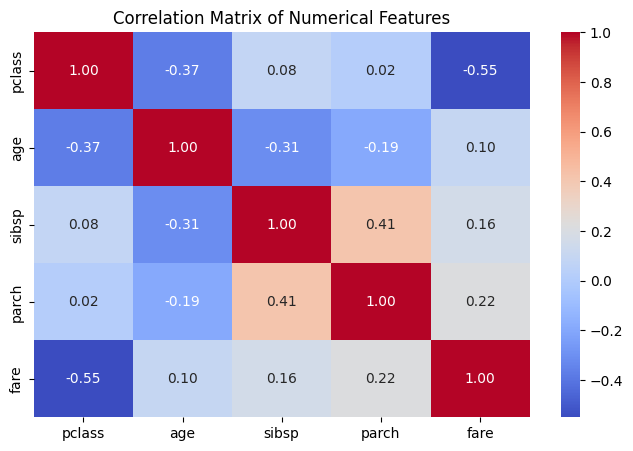


Training rows: 712, Testing rows: 179

Processed Training Shape: (712, 12)
Processed Testing Shape: (179, 12)

Pipeline Verification Accuracy: 0.7933


In [1]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 2. Load a Complex Tabular Dataset
df = sns.load_dataset('titanic')

# Select relevant features and target (dropping redundant/leaky columns)
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
target = 'survived'

X = df[features].copy()
y = df[target].copy()

print("Dataset Shape:", X.shape)
print("\nMissing Values Before Preprocessing:\n", X.isnull().sum())

# 3. Correlation Analysis (Numerical Features)
plt.figure(figsize=(8, 5))
numeric_df = X.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")
plt.show()

# 4. Train/Test Split FIRST (Prevents Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining rows: {X_train.shape[0]}, Testing rows: {X_test.shape[0]}")

# 5. Define Numerical and Categorical Columns
num_cols = ['age', 'sibsp', 'parch', 'fare']
cat_cols = ['pclass', 'sex', 'embarked']

# 6. Build Separate Mini-Pipelines
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),   # Fill missing numbers with median
    ('scaler', StandardScaler())                     # Scale numbers to mean=0, std=1
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Fill missing text with mode
    ('encoder', OneHotEncoder(handle_unknown='ignore'))   # Convert categories to binary columns
])

# 7. Combine into a Single ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# 8. Fit ONLY on Training Data, Transform Both Train and Test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

# 9. (Bonus Verification) Attach to a Model to Prove Pipeline Works End-to-End
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

full_pipeline.fit(X_train, y_train)
preds = full_pipeline.predict(X_test)
print(f"\nPipeline Verification Accuracy: {accuracy_score(y_test, preds):.4f}")
